In [1]:
# 4.7 Capacity assessment: P(day > 650k) under different assumptions and over the next decade
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

file_rotterdamPortData = r'..\data\rotterdam_dataset_16.xlsx'
wd = pd.read_excel(file_rotterdamPortData)

params = {
    'Container': {'lam': 5.5812, 'mu': 9.6069, 'sigma': 0.3493},
    'Tanker': {'lam': 2.2299, 'mu': 10.9119, 'sigma': 0.2963},
    'Bulk': {'lam': 2.2947, 'mu': 10.4989, 'sigma': 0.3806},
}
types = ['Container', 'Tanker', 'Bulk']
days_in_year = 365
capacity = 650000
capacity_new = 800000

def simPoissonProcess(lam, t, rng):
    intArrivalTimsDist = stats.expon(scale=1/lam)
    Nt = 0
    time = intArrivalTimsDist.rvs(random_state=rng)
    while time < t:
        Nt += 1
        time += intArrivalTimsDist.rvs(random_state=rng)
    return Nt

In [2]:
# Monthly rates (same as seasonal scenario): arrivals in month m / days in month m
date_range = pd.date_range(wd['Arrival_Date'].min(), wd['Arrival_Date'].max(), freq='D')
days_per_month = date_range.to_series().groupby(date_range.month).size()
monthly_count = {t: wd[wd['Vessel_Type'] == t].groupby(wd['Arrival_Date'].dt.month).size() for t in types}
lam_month = {t: {m: monthly_count[t].get(m, 0) / days_per_month[m] for m in range(1, 13)} for t in types}

# Constant rates written per month, so one simulation function covers both
lam_const = {t: {m: params[t]['lam'] for m in range(1, 13)} for t in types}

# Cargo distributions: lognormal (basic) and gamma for bulk (method of moments: same mean and variance)
lognorm_dist = {t: stats.lognorm(s=params[t]['sigma'], scale=np.exp(params[t]['mu'])) for t in types}
m_bulk, v_bulk = lognorm_dist['Bulk'].mean(), lognorm_dist['Bulk'].var()
gamma_bulk = stats.gamma(m_bulk**2 / v_bulk, scale=v_bulk / m_bulk)
gamma_dist = {'Container': lognorm_dist['Container'], 'Tanker': lognorm_dist['Tanker'], 'Bulk': gamma_bulk}

print(pd.DataFrame(lam_month).round(3))

    Container  Tanker   Bulk
1       4.495   2.032  2.032
2       4.847   1.953  2.082
3       5.484   2.226  2.301
4       5.122   2.156  2.067
5       6.419   2.473  2.903
6       6.267   2.911  2.522
7       6.882   2.548  2.484
8       6.645   2.280  2.581
9       5.289   2.033  2.156
10      5.516   2.129  2.398
11      5.189   2.233  2.244
12      4.742   1.774  1.742


In [3]:
# Daily throughput for nr_years years
# Per month: N ~ simPoissonProcess(lambda_m, days in month); given N, arrival times are iid uniform in that month
month_days = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
month_start = np.cumsum([0] + month_days[:-1])
month_time_dist = [stats.uniform(loc=month_start[m], scale=month_days[m]) for m in range(12)]

def simDailyThroughput(lam_by_month, cargo_dist, nr_years, rng):
    daily = np.zeros((nr_years, days_in_year))
    for r in range(nr_years):
        for t in types:
            for m in range(12):
                n = simPoissonProcess(lam_by_month[t][m + 1], month_days[m], rng)
                times = month_time_dist[m].rvs(size=n, random_state=rng)
                cargo = cargo_dist[t].rvs(size=n, random_state=rng)
                daily[r] += np.bincount(np.floor(times).astype(int), weights=cargo, minlength=days_in_year)
    return daily

def congestion_stats(daily, cap):
    exceed = daily > cap
    p = exceed.mean()
    half_width = 1.96 * exceed.std(ddof=1) / np.sqrt(exceed.size)
    days_per_year = exceed.sum(axis=1)
    return {'P(day > cap)': p, 'CI low': p - half_width, 'CI high': p + half_width,
            'Days/year': days_per_year.mean(), 'P(no congestion year)': np.mean(days_per_year == 0)}

In [4]:
# Sensitivity to model assumptions (1000 years = 365,000 days each, own seed per model)
nr_years = 1000

daily = {}
daily['Basic (constant, lognormal)'] = simDailyThroughput(lam_const, lognorm_dist, nr_years, np.random.default_rng(1))
daily['Seasonal rates']               = simDailyThroughput(lam_month, lognorm_dist, nr_years, np.random.default_rng(2))
daily['Gamma bulk']                   = simDailyThroughput(lam_const, gamma_dist, nr_years, np.random.default_rng(3))

sens_table = pd.DataFrame([{'Model': k, **congestion_stats(v, capacity)} for k, v in daily.items()])
print(sens_table.to_string(index=False, float_format='{:,.4f}'.format))

# Observed in the data
obs_daily = wd.groupby(wd['Arrival_Date'].dt.normalize())['Cargo_tons'].sum()
obs_daily = obs_daily.reindex(pd.date_range('2022-01-01', '2024-12-31'), fill_value=0)
print('\nobserved P(day > 650k):', round(np.mean(obs_daily > capacity), 4), '(', np.sum(obs_daily > capacity), 'days )')

                      Model  P(day > cap)  CI low  CI high  Days/year  P(no congestion year)
Basic (constant, lognormal)        0.0058  0.0056   0.0061     2.1330                 0.1100
             Seasonal rates        0.0079  0.0076   0.0082     2.8740                 0.0640
                 Gamma bulk        0.0055  0.0053   0.0058     2.0120                 0.1310

observed P(day > 650k): 0.0091 ( 10 days )


In [5]:
# Seasonal model: congestion days per calendar month
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_of_day = np.repeat(np.arange(12), month_days)

cong_month = {}
for k in ['Basic (constant, lognormal)', 'Seasonal rates']:
    exceed = daily[k] > capacity
    cong_month[k] = [exceed[:, month_of_day == m].sum(axis=1).mean() for m in range(12)]

obs_exceed = obs_daily[obs_daily > capacity]
cong_month['Observed (per year)'] = [np.sum(obs_exceed.index.month == m + 1) / 3 for m in range(12)]

cong_month_table = pd.DataFrame(cong_month, index=month_names)
print(cong_month_table.round(3))
print('summer (May-Aug) share of congestion days, seasonal model:',
      round(cong_month_table['Seasonal rates'].iloc[4:8].sum() / cong_month_table['Seasonal rates'].sum(), 3))

     Basic (constant, lognormal)  Seasonal rates  Observed (per year)
Jan                        0.172           0.056                0.000
Feb                        0.142           0.047                0.000
Mar                        0.193           0.165                1.000
Apr                        0.175           0.085                0.000
May                        0.175           0.565                1.000
Jun                        0.162           0.663                0.000
Jul                        0.168           0.540                0.667
Aug                        0.211           0.360                0.000
Sep                        0.164           0.075                0.000
Oct                        0.186           0.147                0.333
Nov                        0.174           0.140                0.333
Dec                        0.211           0.031                0.000
summer (May-Aug) share of congestion days, seasonal model: 0.74


In [6]:
# Next decade: arrival rates grow by g per year (seasonal model, lognormal cargo, 500 years each)
growth_cases = [(0.02, 5), (0.01, 10), (0.02, 10), (0.03, 10)]

rows = []
for i, (g, k) in enumerate(growth_cases):
    lam_grow = {t: {m: lam_month[t][m] * (1 + g)**k for m in range(1, 13)} for t in types}
    d = simDailyThroughput(lam_grow, lognorm_dist, 500, np.random.default_rng(10 + i))
    s650 = congestion_stats(d, capacity)
    s800 = congestion_stats(d, capacity_new)
    rows.append({'Growth/year': g, 'Year': k,
                 'P(day > 650k)': s650['P(day > cap)'], 'Days/year 650k': s650['Days/year'],
                 'P(day > 800k)': s800['P(day > cap)'], 'Days/year 800k': s800['Days/year']})

s650 = congestion_stats(daily['Seasonal rates'], capacity)
s800 = congestion_stats(daily['Seasonal rates'], capacity_new)
rows.insert(0, {'Growth/year': 0.0, 'Year': 0, 'P(day > 650k)': s650['P(day > cap)'], 'Days/year 650k': s650['Days/year'],
                'P(day > 800k)': s800['P(day > cap)'], 'Days/year 800k': s800['Days/year']})

growth_table = pd.DataFrame(rows)
print(growth_table.to_string(index=False, float_format='{:,.4f}'.format))

 Growth/year  Year  P(day > 650k)  Days/year 650k  P(day > 800k)  Days/year 800k
      0.0000     0         0.0079          2.8740         0.0006          0.2140
      0.0200     5         0.0169          6.1800         0.0015          0.5320
      0.0100    10         0.0168          6.1500         0.0016          0.5920
      0.0200    10         0.0327         11.9240         0.0040          1.4440
      0.0300    10         0.0607         22.1680         0.0093          3.4020


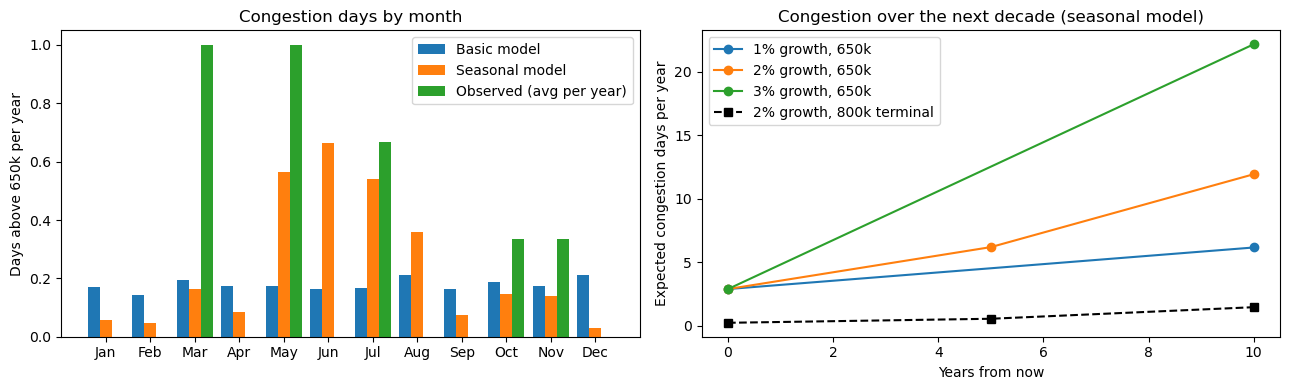

In [7]:
# Plots: congestion days per month, and congestion days per year over the decade
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

x = np.arange(12)
ax[0].bar(x - 0.27, cong_month_table['Basic (constant, lognormal)'], width=0.27, label='Basic model')
ax[0].bar(x, cong_month_table['Seasonal rates'], width=0.27, label='Seasonal model')
ax[0].bar(x + 0.27, cong_month_table['Observed (per year)'], width=0.27, label='Observed (avg per year)')
ax[0].set_xticks(x)
ax[0].set_xticklabels(month_names)
ax[0].set_ylabel('Days above 650k per year')
ax[0].set_title('Congestion days by month')
ax[0].legend()

for g in [0.01, 0.02, 0.03]:
    sub = growth_table[(growth_table['Growth/year'] == g) | (growth_table['Year'] == 0)]
    ax[1].plot(sub['Year'], sub['Days/year 650k'], marker='o', label=f'{int(g*100)}% growth, 650k')
sub = growth_table[(growth_table['Growth/year'] == 0.02) | (growth_table['Year'] == 0)]
ax[1].plot(sub['Year'], sub['Days/year 800k'], marker='s', ls='--', color='k', label='2% growth, 800k terminal')
ax[1].set_xlabel('Years from now')
ax[1].set_ylabel('Expected congestion days per year')
ax[1].set_title('Congestion over the next decade (seasonal model)')
ax[1].legend()
plt.tight_layout()
plt.show()